In [1]:
import json, math, random, warnings
from dataclasses import dataclass
from typing import Dict, List, Optional, Tuple
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from transformers import AutoTokenizer
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

In [2]:
warnings.filterwarnings("ignore")
torch.manual_seed(42)
random.seed(42)
np.random.seed(42)

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() else "cpu"
)

print(f"Using device: {DEVICE}")

# 1) Architecture Overview

A VLM answers the question: *"how do we give a text-generating LLM the ability to see?"*

<img src="https://miro.medium.com/v2/resize:fit:600/1*u1ywe8Qf5Glt95Qt6JMxwg.png" width=500>

1. **Vision encoder** – Chop an image into patches; transform them into dense vectors.
   SigLIP (used by Qwen2.5-VL) is a ViT trained with a sigmoid contrastive loss
   rather than softmax, producing richer per-patch representations.

2. **MLP projector** – Map patch vectors from `visual_dim → llm_dim`.
   The LLM and ViT were trained independently; their embedding spaces are misaligned.
   The projector is the *learned translator*. During Stage 1, it is the **only**
   component trained; everything else stays frozen.

3. **Language model** – A standard causal transformer that sees a flattened token
   sequence of the form:
   ```
   [<|vision_start|>] [v₁ … vₙ] [<|vision_end|>] [text tokens …]
   ```
   The multimodal rotary position embedding (mRoPE) gives each token a 3-D position
   `(time, height, width)` so the LLM can reason about spatial layout.

In [3]:
@dataclass
class VLMConfig:
    """
    Same architecture shape as a real LLaVA-style VLM built on
    google/siglip-base-patch16-224 (vision) + Qwen/Qwen2.5-0.5B (language)
    """

    # ── Vision encoder
    image_size: int = 64  # (H = W, square for simplicity)
    patch_size: int = 16  # patch size is resolution-independent
    visual_dim: int = 256  # ViT hidden
    visual_num_heads: int = 4
    visual_num_layers: int = 3

    # ── MLP projector
    projector_hidden_dim: int = 512

    # ── Language model
    llm_dim: int = 192
    llm_num_heads: int = 4
    llm_num_kv_heads: int = (
        2  # GQA — fewer K/V heads than Q heads, shared via repeat_kv
    )
    llm_num_layers: int = 4
    llm_ffn_dim: int = 512
    vocab_size: int = 30522
    max_seq_len: int = 512

    # ── mRoPE
    rope_base: float = 10000.0  # real Qwen2.5 rope_theta: 1,000,000

    # ── Special token IDs
    # BERT unused tokens — safe to repurpose, never in real text.
    vision_start_id: int = 1
    vision_end_id: int = 2
    image_pad_id: int = 3
    pad_token_id: int = 0

    @property
    def num_patches(self) -> int:
        return (self.image_size // self.patch_size) ** 2

    @property
    def patch_grid_hw(self) -> Tuple[int, int]:
        g = self.image_size // self.patch_size
        return (g, g)

    @property
    def head_dim(self) -> int:
        return self.llm_dim // self.llm_num_heads

    @property
    def num_kv_groups(self) -> int:
        """How many Q heads share each K/V head (GQA repetition factor)."""
        return self.llm_num_heads // self.llm_num_kv_heads


cfg = VLMConfig()
print(f"Patch grid : {cfg.patch_grid_hw}  →  {cfg.num_patches} tokens per image")
print(
    f"GQA groups : {cfg.llm_num_heads} query heads share {cfg.llm_num_kv_heads} KV heads "
    f"({cfg.num_kv_groups}x repetition)"
)

Patch grid : (4, 4)  →  16 tokens per image
GQA groups : 4 query heads share 2 KV heads (2x repetition)


## 1.1 Vision Encoder

| Choice | Vanilla ViT | SigLIP / Qwen2.5-VL | Reason |
|---|---|---|---|
| Activation | GELU | **SwiGLU** | higher capacity per parameter |
| Pooling | [CLS] token | **all patch tokens** | preserves spatial layout for grounding |
| Contrastive loss | softmax | sigmoid | allows multiple matches per image |
| Pos. embed | learned absolute | Qwen uses **mRoPE** inside LLM | flexibility for variable resolution |

**SwiGLU**: `FFN(x) = down(SiLU(gate(x)) ⊙ up(x))`

The *gate* path learns *what* information to pass through; the *up* path carries the actual content.


In [4]:
class SwiGLU(nn.Module):
    def __init__(self, embed_dim: int, hidden_dim: int):
        super().__init__()
        self.gate_proj = nn.Linear(embed_dim, hidden_dim, bias=False)
        self.up_proj = nn.Linear(embed_dim, hidden_dim, bias=False)
        self.down_proj = nn.Linear(hidden_dim, embed_dim, bias=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Input: (batch_num, num_tokens, embed_dim)
        # Output: (batch_num, num_tokens, hidden_dim)
        gate = F.silu(self.gate_proj(x))
        up = self.up_proj(x)

        # Output: (batch_num, num_tokens, embed_dim)
        return self.down_proj(gate * up)

In [5]:
class ViTAttention(nn.Module):
    def __init__(self, embed_dim: int, num_heads: int):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.scale = self.head_dim**-0.5
        self.qkv = nn.Linear(embed_dim, 3 * embed_dim, bias=True)
        self.proj = nn.Linear(embed_dim, embed_dim, bias=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        For images, the sequence length equals the number of patches.
        Each patch acts as one "token", just like a word-token in text.
        So num_patches here plays the same role that seq_len / num_tokens does in NLP.
        """

        batch_num, num_tokens, embed_dim = x.shape

        # Fused QKV projection, then reshape for multi-head split
        # Input: (batch_num, num_tokens, embed_dim)
        # Output (batch_num, num_tokens, 3 * embed_dim)
        qkv = self.qkv(x)

        # Input: (batch_num, num_tokens, 3, num_heads, head_dim)
        # Output: (3, batch_num, num_heads, num_tokens, head_dim)
        qkv = qkv.reshape(
            batch_num, num_tokens, 3, self.num_heads, self.head_dim
        ).permute(2, 0, 3, 1, 4)
        q, k, v = qkv.unbind(0)

        # Scaled dot-product attention — fully bidirectional (no mask)
        # (batch_num, num_heads, num_tokens, num_tokens)
        attn = F.softmax((q @ k.transpose(-2, -1)) * self.scale, dim=-1)

        # Input: (batch_num, num_heads, num_tokens, head_dim)
        # Output: (batch_num, num_tokens, embed_dim)
        x = (attn @ v).transpose(1, 2).reshape(batch_num, num_tokens, embed_dim)

        # Input: (batch_num, num_tokens, embed_dim)
        # Output: (batch_num, num_tokens, embed_dim)
        return self.proj(x)


class ViTBlock(nn.Module):
    """
    Single ViT transformer block
    Pre-norm design for training stability.
    Post-norm: avoids gradient explosion.
    """

    def __init__(self, embed_dim: int, num_heads: int, ffn_hidden: int):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = ViTAttention(embed_dim, num_heads)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.ffn = SwiGLU(embed_dim, ffn_hidden)

    def forward(self, x: torch.Tensor) -> torch.Tensor:

        # Pre-norm attention with residual
        # Input: (batch_num, num_tokens, embed_dim)
        # Output: (batch_num, num_tokens, embed_dim)
        x = x + self.attn(self.norm1(x))

        # Pre-norm SwiGLU FFN with residual
        x = x + self.ffn(self.norm2(x))
        return x

In [6]:
class TinyViT(nn.Module):
    """
    Minimal SigLIP-style Vision Transformer.
    SigLIP-style ViT, returns ALL patch tokens (no CLS token)

    Differences from vanilla ViT:
    - NO [CLS] token  → returns spatial patch features for grounding
    - SwiGLU FFN      → higher capacity per parameter
    - Conv2d patch embed → equivalent to linear but GPU-friendly
    """

    def __init__(self, cfg: VLMConfig):
        super().__init__()
        self.patch_size = cfg.patch_size
        self.num_patches = cfg.num_patches

        # Conv2d patch embedding, trick to cut the image into non-overlapping patches
        # Input: (B, 3, H, W)
        # Output: (B, visual_dim, H/p, W/p)
        self.patch_embed = nn.Conv2d(
            3, cfg.visual_dim, kernel_size=cfg.patch_size, stride=cfg.patch_size
        )

        # Absolute positional embedding (one vector per patch position)
        self.pos_embed = nn.Parameter(
            torch.randn(1, cfg.num_patches, cfg.visual_dim) * 0.02
        )

        # SwiGLU hidden dim: using 4x width, halved because SwiGLU has 2 projections
        ffn_hidden = cfg.visual_dim * 2
        self.blocks = nn.ModuleList(
            [
                ViTBlock(cfg.visual_dim, cfg.visual_num_heads, ffn_hidden)
                for _ in range(cfg.visual_num_layers)
            ]
        )
        self.norm = nn.LayerNorm(cfg.visual_dim)

        # Same std=0.02 scaled init used by real ViT / SigLIP implementations
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(module: nn.Module) -> None:
        if isinstance(module, (nn.Linear, nn.Conv2d)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)

    def forward(self, pixel_values: torch.Tensor) -> torch.Tensor:
        """
        Args:
            pixel_values: (batch_num, 3, image_size, image_size)
        Returns:
            visual_features: (batch_num, num_patches, visual_dim)
        """
        # Input: (batch_num, 3, H, W)
        # Output: (batch_num, visual_dim, H/p, W/p)
        x = self.patch_embed(pixel_values)

        # Flatten spatial dims and transpose
        # (batch_num, num_patches, visual_dim)
        x = x.flatten(2).transpose(1, 2)

        # Add spatial positional bias (broadcast over batch)
        # (batch_num, num_patches, visual_dim) + (1, num_patches, visual_dim)
        x = x + self.pos_embed

        # Apply transformer encoder blocks
        for block in self.blocks:
            # (batch_num, num_patches, visual_dim)
            x = block(x)

        # Final layer norm
        return self.norm(x)


# Test
vit = TinyViT(cfg).to(DEVICE)
dummy_img = torch.randn(2, 3, cfg.image_size, cfg.image_size).to(DEVICE)
vis_out = vit(dummy_img)
print(f"TinyViT  {tuple(dummy_img.shape)} → {tuple(vis_out.shape)}")
print(f"Params   {sum(p.numel() for p in vit.parameters()):,}")

TinyViT  (2, 3, 64, 64) → (2, 16, 256)
Params   2,173,696


## 1.2 MLP Projector — Trainable Bridge (Stage 1 only)

### Why not a single linear layer?

1. A single linear map `W: R^{visual_dim} → R^{llm_dim}` can only learn
*rotations and scalings* of the visual feature space.  
2. The ViT and LLM have completely different training objectives; their spaces are
non-linearly misaligned. 
3. The 2-layer MLP with GELU introduces the nonlinearity
needed to learn a more expressive alignment.
4. **Layer norm** after the second projection stabilises early training — gradient
norms through the LLM embedding lookup can be large initially.


In [7]:
# 2-layer MLP projector: the ONLY trainable component in Stage 1.
class MLPProjector(nn.Module):
    """
    visual_dim → hidden_dim → llm_dim  (with GELU + LayerNorm)

    Stage 1 role: translate frozen ViT features into the LLM's token space.
    Stage 2+ role: continues to train alongside the LLM.
    """

    def __init__(self, visual_dim: int, llm_dim: int, hidden_dim: int):
        super().__init__()
        self.fc1 = nn.Linear(visual_dim, hidden_dim)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden_dim, llm_dim)

        # Post-projection norm stabilises LLM input magnitudes
        self.norm = nn.LayerNorm(llm_dim)

    def forward(self, visual_features: torch.Tensor) -> torch.Tensor:
        """
        Args:
            visual_features: (batch_num, num_patches, visual_dim)
        Returns:
            projected: (batch_num, num_patches, llm_dim)
        """

        # Input: (batch_num, num_patches, visual_dim)
        # Output: (batch_num, num_patches, hidden_dim)
        x = self.fc1(visual_features)
        x = self.act(x)

        # (batch_num, num_patches, llm_dim)
        x = self.fc2(x)
        return self.norm(x)


projector = MLPProjector(cfg.visual_dim, cfg.llm_dim, cfg.projector_hidden_dim)
projector = projector.to(DEVICE)
proj_out = projector(vis_out)

print(f"Projector {tuple(vis_out.shape)} → {tuple(proj_out.shape)}")
print(f"Params    {sum(p.numel() for p in projector.parameters()):,}")

Projector (2, 16, 256) → (2, 16, 192)
Params    230,464


# 2) Data Handling

Real VLMs handle images of *arbitrary* resolution. A 224×224 thumbnail and a
1344×896 document scan should both be processable. The number of patch tokens
scales with image area: `N = (H/p) × (W/p)`.

For the from-scratch sections we use a **synthetic dataset**: solid-colored
64×64 images paired with color-name captions. It needs no downloads and is small
enough to overfit quickly, which lets us *verify* the plumbing — tokenisation,
visual token insertion, attention masking, loss masking — in isolation.

| Color | RGB | Caption |
|---|---|---|
| red | (220, 50, 50) | `"this image shows a red background"` |
| blue | (50, 100, 220) | `"this image shows a blue background"` |
| … | … | … |

**Why synthetic here?** Because at this point the encoder and the LLM are both
randomly initialised, so *no* dataset could produce real captions — the only
question worth asking is whether the pipeline is wired correctly. Section 5.3
swaps in a real photo/caption dataset once there are pretrained backbones that
can actually make use of it.

Note the contract this dataset defines — each item is a
`{'image': Tensor, 'caption': str}` dict. The real dataset in Section 5.3
returns the same shape, which is why `collate_vlm_batch` below serves both
without modification.

## 2.1 Dynamic Resolution

Image  shape : torch.Size([3, 64, 64])
Caption      : 'this image shows a blue background'
Dataset size : 300


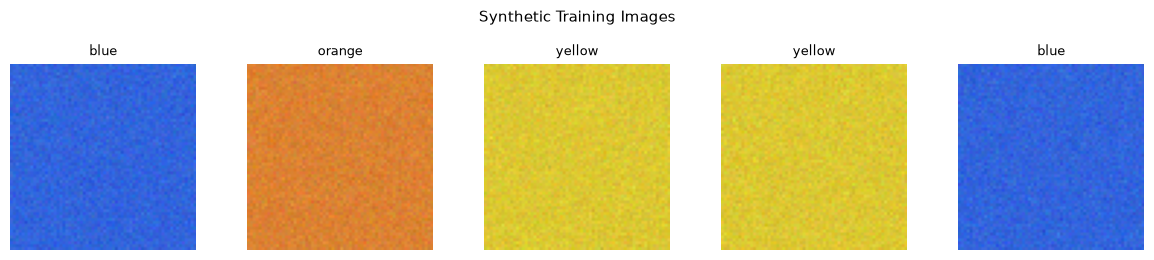

In [8]:
# Color palette used for synthetic image generation.
# Simple enough to overfit; varied enough to test generalisation.

COLORS: Dict[str, Tuple[int, int, int]] = {
    "red": (220, 50, 50),
    "blue": (50, 100, 220),
    "green": (50, 180, 50),
    "yellow": (220, 200, 50),
    "purple": (150, 50, 200),
    "orange": (220, 130, 50),
    "pink": (220, 100, 150),
    "cyan": (50, 200, 200),
    "white": (240, 240, 240),
    "gray": (128, 128, 128),
}


class SyntheticColorDataset(Dataset):
    """
    Synthetic (image, caption) pairs — no downloads required.

    Image : 64x64 solid color + Gaussian noise (prevents trivial pixel shortcuts)
    Caption: "this image shows a <color> background"
    """

    def __init__(self, num_samples: int = 300, image_size: int = 64):
        self.image_size = image_size
        self.color_names = list(COLORS.keys())
        rng = random.Random(42)
        self.samples = [rng.choice(self.color_names) for _ in range(num_samples)]

    def __len__(self) -> int:
        return len(self.samples)

    def _make_image(self, color_name: str) -> torch.Tensor:
        rgb = COLORS[color_name]

        # Fill canvas with target color + small Gaussian noise
        # (image_size, image_size, 3) normalised to [0, 1]
        canvas = np.full((self.image_size, self.image_size, 3), rgb, dtype=np.float32)
        canvas += np.random.randn(*canvas.shape).astype(np.float32) * 8.0
        canvas = np.clip(canvas, 0.0, 255.0) / 255.0

        # (image_size, image_size, 3) → (3, image_size, image_size)
        return torch.from_numpy(canvas.transpose(2, 0, 1))

    def __getitem__(self, idx: int) -> Dict[str, object]:
        color = self.samples[idx]
        return {
            "image": self._make_image(color),
            "caption": f"this image shows a {color} background",
            "color": color,
        }


# Preview the dataset
dataset = SyntheticColorDataset(num_samples=300, image_size=cfg.image_size)
sample = dataset[0]
print(f"Image  shape : {sample['image'].shape}")
print(f"Caption      : {sample['caption']!r}")
print(f"Dataset size : {len(dataset)}")

# Visualise a few samples
fig, axes = plt.subplots(1, 5, figsize=(12, 2.5))
for ax, idx in zip(axes, [0, 30, 60, 90, 120]):
    s = dataset[idx]
    ax.imshow(s["image"].permute(1, 2, 0).numpy())
    ax.set_title(s["color"], fontsize=9)
    ax.axis("off")
plt.suptitle("Synthetic Training Images", fontsize=11, y=1.02)
plt.tight_layout()
plt.show()

## 2.2 Tokenization

In [9]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

# Verify the special-token IDs we reserved in VLMConfig
special_token = [
    ("<|vision_start|>", cfg.vision_start_id),
    ("<|vision_end|>", cfg.vision_end_id),
    ("<|image_pad|>", cfg.image_pad_id),
]

print("Special token IDs:")
for name, tok_id in special_token:
    decoded = tokenizer.decode([tok_id])
    print(f"  {name:20s} id = {tok_id:5d}  decoded={decoded!r}")

Special token IDs:
  <|vision_start|>     id =     1  decoded='[unused0]'
  <|vision_end|>       id =     2  decoded='[unused1]'
  <|image_pad|>        id =     3  decoded='[unused2]'


**Visual Token Insertion**

The LLM operates on a flat 1-D token sequence. Visual tokens must be *injected*
into that sequence in a way the LLM can distinguish from regular text.
Qwen2.5-VL uses three special tokens:

```
<|vision_start|>  v₁  v₂  …  vₙ  <|vision_end|>  text tokens …
      ↑                                  ↑
  boundary marker             boundary marker
```

After token-ID construction, the embedding layer replaces:
- `vision_start_id`, `vision_end_id`, `image_pad_id` → their token embeddings
- The actual visual patch embeddings overwrite the `image_pad_id` positions at
  embedding time (not at token-ID time).


```
Input : num_patches=16, caption_ids=[4, 5, 6, 7, 8]
Output: [1, 3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3, 2, 4, 5, 6, 7, 8]
         ↑  ←─ 16 image_pad placeholders ──→  ↑  ← text →
      vis_start                            vis_end
```


In [10]:
# Build the mixed token-ID sequence:
# [<vis_start>] + [image_pad × N_patches] + [<vis_end>] + [text_ids]
def build_token_ids_with_visual(
    caption_ids: List[int],
    num_patches: int,
    cfg: VLMConfig,
) -> Tuple[torch.Tensor, int, int]:
    """
    Construct the interleaved token-ID sequence for a single example.

    Returns:
        token_ids  : (seq_len,) int64 token IDs
        vis_start  : index of <|vision_start|> in token_ids
        vis_end    : index of <|vision_end|>   in token_ids
    """

    vis_start_idx = 0
    # Placeholder patch positions immediately after the start marker
    patch_ids = [cfg.image_pad_id] * num_patches
    vis_end_idx = 1 + num_patches

    id_list = [cfg.vision_start_id] + patch_ids + [cfg.vision_end_id] + caption_ids

    # (seq_len,)
    token_ids = torch.tensor(id_list, dtype=torch.long)
    return token_ids, vis_start_idx, vis_end_idx


def get_eos_id(tokenizer) -> int:
    """
    End-of-caption marker, resolved per tokenizer family.
    BERT has no eos_token_id (it uses [SEP]); Qwen and most causal LMs do.
    Appending it teaches the model when to *stop* captioning.
    """
    return (
        tokenizer.eos_token_id
        if tokenizer.eos_token_id is not None
        else tokenizer.sep_token_id
    )


def collate_vlm_batch(
    examples: List[Dict],
    tokenizer,
    cfg: VLMConfig,
) -> Dict[str, torch.Tensor]:
    """
    Args:
        examples : list of {'image': Tensor, 'caption': str} dicts
    Returns dict with keys:
        pixel_values   : (batch_num, 3, H, W)
        input_ids      : (batch_num, seq_len)  – padded
        attention_mask : (batch_num, seq_len)  – 1 = real token, 0 = padding
        labels         : (batch_num, seq_len)  – -100 except caption tokens
        vis_ranges     : (batch_num, 2)        – (vis_start, vis_end) indices
    """
    batch_num = len(examples)
    eos_id = get_eos_id(tokenizer)

    # Stack images into a single batch tensor
    # (batch_num, 3, image_size, image_size)
    pixel_values = torch.stack([ex["image"] for ex in examples])

    # Tokenise captions (no special tokens — we insert our own)
    all_token_ids, all_vis_ranges, all_labels = [], [], []

    for ex in examples:
        cap_ids = tokenizer.encode(ex["caption"], add_special_tokens=False) + [eos_id]

        # patch the image with placeholder, will be replaced with visual embed later
        token_ids, v_start, v_end = build_token_ids_with_visual(
            cap_ids, cfg.num_patches, cfg
        )

        # Label mask: -100 suppresses loss on everything except the caption
        labels = torch.full_like(token_ids, -100)
        caption_start = v_end + 1
        labels[caption_start:] = token_ids[caption_start:]

        all_token_ids.append(token_ids)
        all_vis_ranges.append((v_start, v_end))
        all_labels.append(labels)

    # Pad sequences to the longest in this batch
    max_len = max(t.size(0) for t in all_token_ids)

    def pad(tensor_list: List[torch.Tensor], pad_val: int) -> torch.Tensor:
        padded = torch.full((batch_num, max_len), pad_val, dtype=torch.long)
        for i, t in enumerate(tensor_list):
            padded[i, : t.size(0)] = t
        return padded

    # Built from each example's true length rather than `input_ids != pad_id`:
    # for Qwen, pad_token_id == eos_token_id, and every real caption also ends
    # in EOS — comparing against pad_id would wrongly mask that final token.
    # (batch_num, seq_len)
    attention_mask = torch.zeros((batch_num, max_len), dtype=torch.long)
    for i, t in enumerate(all_token_ids):
        attention_mask[i, : t.size(0)] = 1

    return {
        "pixel_values": pixel_values,  # (batch_num, 3, H, W)
        "input_ids": pad(all_token_ids, cfg.pad_token_id),  # (batch_num, seq_len)
        "attention_mask": attention_mask,  # (batch_num, seq_len)
        "labels": pad(all_labels, -100),  # (batch_num, seq_len)
        "vis_ranges": torch.tensor(all_vis_ranges, dtype=torch.long),  # (batch_num, 2)
    }


# Demo
cap_ids = tokenizer.encode(
    "this image shows a red background", add_special_tokens=False
)
token_ids, v_start, v_end = build_token_ids_with_visual(cap_ids, cfg.num_patches, cfg)

print(f"Sequence length : {token_ids.size(0)}")

print(f"[0]: {token_ids[0].item()} = <|vision_start|>")
print(
    f"[1 .. {v_end-1}]: {token_ids[1:v_end].tolist()} = image_pad × {cfg.num_patches}"
)

print(f"[{v_end}]: {token_ids[v_end].item()} = <|vision_end|>")
print(f"[{v_end+1}..]: {token_ids[v_end+1:].tolist()} = caption tokens")

Sequence length : 24
[0]: 1 = <|vision_start|>
[1 .. 16]: [3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3] = image_pad × 16
[17]: 2 = <|vision_end|>
[18..]: [2023, 3746, 3065, 1037, 2417, 4281] = caption tokens


# 3) Multimodal Rotary Position Embeddings (mRoPE)

Standard 1-D RoPE encodes a single integer position for each token.
For images, position has *two* spatial dimensions (row, col). For video it has
three: (time, row, col). Qwen2.5-VL's **mRoPE** extends RoPE to 3-D:

```
position_ids shape: (3, seq_len)
  dim 0 → time   positions
  dim 1 → height positions
  dim 2 → width  positions
```

The attention head dimension `head_dim` is split into **3 equal sections**; each
section receives RoPE computed from one of the three coordinates.

### Position assignment rules

| Token type | time | height | width |
|---|---|---|---|
| `<\|vision_start\|>` | 0 | 0 | 0 |
| visual patch at row r, col c | 0 | r | c |
| `<\|vision_end\|>` | 0 | H_grid | W_grid |
| text token at position t | t | t | t |

Text tokens use the **same value** for all three dimensions — this degenerates
to standard 1-D RoPE for text, maintaining compatibility with a pretrained LLM.

## Sample I/O

```
Grid: 4×4 image, text length 5
position_ids: shape (3, 22)   [1 + 16 patches + 1 + 5 text − 1 for 0-index]
  time   : [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 5, 6, 7, 8, 9]
  height : [0, 0, 0, 0, 0, 1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3, 4, 5, 6, 7, 8, 9]
  width  : [0, 0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3, 0, 5, 6, 7, 8, 9]
```


In [11]:
# Compute inverse frequency bands for one mRoPE component.
def get_rope_inv_freq(
    dim: int,
    base: float = 10000.0,
    device: torch.device = torch.device("cpu"),
) -> torch.Tensor:
    """
    Standard RoPE inverse frequencies for a single dimension.

    The formula θ_i = base^{-2i/dim} gives exponentially spaced frequencies,
    enabling the model to encode both fine-grained and coarse position differences.

    Args:
        dim : number of dimensions for this component (head_dim // 3)
    Returns:
        inv_freq: (dim // 2,)  — one frequency per rotation pair
    """
    # (dim // 2,)  — indices 0, 2, 4, …, dim-2
    exponents = torch.arange(0, dim, 2, dtype=torch.float32, device=device)

    # (dim // 2,)
    inv_freq = 1.0 / (base ** (exponents / dim))

    return inv_freq


# Compute 3D position IDs for the full interleaved sequence.
# Sequence layout: [vis_start | patches | vis_end | text_tokens]
def compute_mrope_position_ids(
    patch_grid_hw: Tuple[int, int],
    text_length: int,
    device: torch.device = torch.device("cpu"),
) -> torch.Tensor:
    """
    Build the (3, seq_len) position-ID matrix.

    Args:
        patch_grid_hw : (H_grid, W_grid) — e.g. (4, 4) for 16 patches
        text_length   : number of text tokens following <|vision_end|>
    Returns:
        position_ids  : (3, seq_len)  — rows are [time, height, width]
    """
    H, W = patch_grid_hw
    num_patches = H * W

    # <|vision_start|> ──────────────────────────────────────────
    # Anchor at origin; the LLM learns that this marks image start.
    # (3, 1)
    vis_start_pos = torch.zeros(3, 1, dtype=torch.long, device=device)

    # Visual patch tokens: 2-D spatial grid ─────────────────────
    # time=0 (static image, not video)
    # height: repeats each row W times   [0,0,0,0, 1,1,1,1, 2,2,2,2, 3,3,3,3]
    # width : cycles 0..W-1 for each row [0,1,2,3, 0,1,2,3, 0,1,2,3, 0,1,2,3]
    time_ids = torch.zeros(num_patches, dtype=torch.long, device=device)
    height_ids = torch.arange(H, device=device).repeat_interleave(W)
    width_ids = torch.arange(W, device=device).repeat(H)

    # (3, num_patches)
    visual_pos = torch.stack([time_ids, height_ids, width_ids], dim=0)

    # <|vision_end|>: sits just outside the grid corner ─────────
    # (3, 1)
    vis_end_pos = torch.tensor([[0], [H], [W]], dtype=torch.long, device=device)

    # Text tokens: all three dims increment together ─────────────
    # This degenerates to standard 1-D RoPE for text
    text_offset = max(H, W) + 1
    text_range = (
        torch.arange(text_length, dtype=torch.long, device=device) + text_offset
    )

    # (3, text_length) — broadcast the 1-D positions to all 3 dims
    text_pos = text_range.unsqueeze(0).expand(3, -1)

    # Concatenate all segments: (3, 1 + num_patches + 1 + text_length)
    position_ids = torch.cat([vis_start_pos, visual_pos, vis_end_pos, text_pos], dim=1)
    return position_ids


def build_mrope_cos_sin(
    position_ids: torch.Tensor,  # (3, seq_len)
    head_dim: int,
    base: float = 10000.0,
) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Compute cos and sin tensors for mRoPE application.

    Returns:
        cos : (seq_len, head_dim)
        sin : (seq_len, head_dim)
    """

    assert head_dim % 6 == 0, (
        f"head_dim {head_dim} must be divisible by 6 "
        f"(3 mRoPE components × 2 for rotate_half)"
    )
    device = position_ids.device
    dim_per_component = head_dim // 3  # 16 for head_dim=48
    seq_len = position_ids.shape[1]

    # Shared inverse frequencies (same for time / height / width)
    # (dim_per_component // 2,)
    inv_freq = get_rope_inv_freq(dim_per_component, base, device)

    cos_parts, sin_parts = [], []
    for coord_idx in range(3):
        # Extract this coordinate's positions: (seq_len,)
        pos = position_ids[coord_idx].float()

        # Outer product → (seq_len, dim_per_component // 2)
        freqs = torch.outer(pos, inv_freq)

        # Duplicate for rotate_half: (seq_len, dim_per_component)
        emb = torch.cat([freqs, freqs], dim=-1)
        cos_parts.append(emb.cos())
        sin_parts.append(emb.sin())

    # Concatenate all 3 components along the feature axis
    # (seq_len, head_dim)
    cos = torch.cat(cos_parts, dim=-1)
    sin = torch.cat(sin_parts, dim=-1)
    return cos, sin

In [12]:
# Apply mRoPE to query and key tensors inside an attention layer.
def rotate_half(x: torch.Tensor) -> torch.Tensor:
    """
    Split the last dimension in half, negate the second half, then swap.
    This implements the 2-D rotation matrix in RoPE.

    (batch_num, num_heads, seq_len, head_dim) → (batch_num, num_heads, seq_len, head_dim)
    """
    half = x.shape[-1] // 2
    # (batch_num, num_heads, seq_len, half)
    x1 = x[..., :half]
    # (batch_num, num_heads, seq_len, half)
    x2 = x[..., half:]
    # (batch_num, num_heads, seq_len, head_dim)
    return torch.cat([-x2, x1], dim=-1)


def apply_mrope(
    q: torch.Tensor,  # (batch_num, num_heads, seq_len, head_dim)
    k: torch.Tensor,  # (batch_num, num_heads, seq_len, head_dim)
    cos: torch.Tensor,  # (seq_len, head_dim)
    sin: torch.Tensor,  # (seq_len, head_dim)
) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Apply mRoPE rotation to Q and K before attention computation.
    Broadcast cos/sin over batch and head dimensions.
    """
    # (seq_len, head_dim) → (1, 1, seq_len, head_dim)  for broadcasting
    cos = cos.unsqueeze(0).unsqueeze(0)
    sin = sin.unsqueeze(0).unsqueeze(0)

    # Modulate each (q, k) vector by its position-dependent rotation
    # Input: (batch_num, num_heads, seq_len, head_dim)
    # Output: (batch_num, num_heads, seq_len, head_dim)
    q_rot = q * cos + rotate_half(q) * sin
    k_rot = k * cos + rotate_half(k) * sin
    return q_rot, k_rot

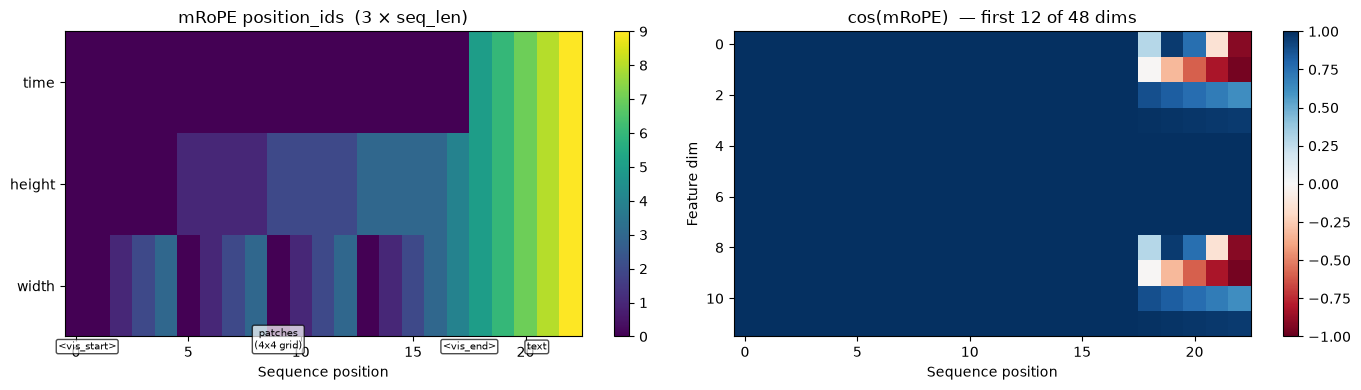

position_ids shape : (3, 23)
cos / sin shape    : (23, 48)


In [13]:
# Demo
pos_ids = compute_mrope_position_ids(cfg.patch_grid_hw, text_length=5)
cos_demo, sin_demo = build_mrope_cos_sin(pos_ids, cfg.head_dim)
seq_len = pos_ids.shape[1]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Position IDs heatmap
im0 = axes[0].imshow(pos_ids.numpy(), aspect="auto", cmap="viridis")
axes[0].set_yticks([0, 1, 2])
axes[0].set_yticklabels(["time", "height", "width"])
axes[0].set_xlabel("Sequence position")
axes[0].set_title("mRoPE position_ids  (3 × seq_len)")
plt.colorbar(im0, ax=axes[0])

# Add region annotations
for label, x0, x1 in [
    ("<vis_start>", 0, 1),
    ("patches\n(4x4 grid)", 1, 17),
    ("<vis_end>", 17, 18),
    ("text", 18, seq_len),
]:
    mid = (x0 + x1) / 2
    axes[0].text(
        mid,
        2.65,
        label,
        ha="center",
        va="bottom",
        fontsize=7,
        bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7),
    )

# cos embedding heatmap (first 12 dims)
im1 = axes[1].imshow(
    cos_demo[:, :12].numpy().T, aspect="auto", cmap="RdBu", vmin=-1, vmax=1
)
axes[1].set_xlabel("Sequence position")
axes[1].set_ylabel("Feature dim")
axes[1].set_title("cos(mRoPE)  — first 12 of 48 dims")
plt.colorbar(im1, ax=axes[1])

plt.tight_layout()
plt.show()
print(f"position_ids shape : {tuple(pos_ids.shape)}")
print(f"cos / sin shape    : {tuple(cos_demo.shape)}")

The LLM uses mRoPE inside every attention layer. The key change vs. standard RoPE:

1. Compute `position_ids` of shape `(3, seq_len)` **once** before the forward pass.
2. Convert to `(cos, sin)` of shape `(seq_len, head_dim)`.
3. Inside each attention layer, apply `apply_mrope(q, k, cos, sin)` **before** computing the attention scores.

Everything else (FFN, residuals, layer norm) is identical to a standard transformer.


In [14]:
def repeat_kv(x: torch.Tensor, n_rep: int) -> torch.Tensor:
    """
    Expand K/V heads by n_rep so they align with the (larger) number of Q heads.
    This is what makes GQA cheap: fewer K/V heads are computed

    Input : (batch_num, num_kv_heads, seq_len, head_dim)
    Output: (batch_num, num_kv_heads * n_rep, seq_len, head_dim)
    """
    if n_rep == 1:
        return x
    batch_num, num_kv_heads, seq_len, head_dim = x.shape

    return (
        x[:, :, None, :, :]
        .expand(batch_num, num_kv_heads, n_rep, seq_len, head_dim)
        .reshape(batch_num, num_kv_heads * n_rep, seq_len, head_dim)
    )


# Multi-head attention with mRoPE + Grouped Query Attention
class MRoPEAttention(nn.Module):
    def __init__(self, cfg: VLMConfig):
        super().__init__()
        self.num_heads = cfg.llm_num_heads
        self.num_kv_heads = cfg.llm_num_kv_heads
        self.num_kv_groups = cfg.num_kv_groups
        self.head_dim = cfg.head_dim
        self.scale = self.head_dim**-0.5

        self.q_proj = nn.Linear(cfg.llm_dim, self.num_heads * self.head_dim, bias=False)
        self.k_proj = nn.Linear(
            cfg.llm_dim, self.num_kv_heads * self.head_dim, bias=False
        )
        self.v_proj = nn.Linear(
            cfg.llm_dim, self.num_kv_heads * self.head_dim, bias=False
        )
        self.out_proj = nn.Linear(
            self.num_heads * self.head_dim, cfg.llm_dim, bias=False
        )

    def forward(
        self,
        x: torch.Tensor,  # (batch_num, seq_len, llm_dim)
        cos: torch.Tensor,  # (seq_len, head_dim)
        sin: torch.Tensor,  # (seq_len, head_dim)
        attn_mask: Optional[torch.Tensor] = None,  # (batch_num, 1, seq_len, seq_len)
    ) -> torch.Tensor:
        batch_num, seq_len, _ = x.shape

        # Project into Q (many heads) and K, V (few heads — GQA)
        # Output: (batch_num, num_heads, seq_len, head_dim)
        q = (
            self.q_proj(x)
            .view(batch_num, seq_len, self.num_heads, self.head_dim)
            .transpose(1, 2)
        )

        # Output: (batch_num, num_kv_heads, seq_len, head_dim)
        k = (
            self.k_proj(x)
            .view(batch_num, seq_len, self.num_kv_heads, self.head_dim)
            .transpose(1, 2)
        )
        v = (
            self.v_proj(x)
            .view(batch_num, seq_len, self.num_kv_heads, self.head_dim)
            .transpose(1, 2)
        )

        # Inject position information via mRoPE rotation
        # cos/sin only span head_dim, so this applies identically to Q and the fewer K heads)
        q, k = apply_mrope(q, k, cos, sin)

        # Broadcast K/V heads up to num_heads so every Q head has a matching K/V head
        # (batch_num, num_kv_heads, seq_len, head_dim) → (batch_num, num_heads, seq_len, head_dim)
        k = repeat_kv(k, self.num_kv_groups)
        v = repeat_kv(v, self.num_kv_groups)

        # Scaled dot-product attention with optional additive mask
        # Output: (batch_num, num_heads, seq_len, seq_len)
        scores = (q @ k.transpose(-2, -1)) * self.scale
        if attn_mask is not None:
            scores = scores + attn_mask  # attn_mask contains 0 or -inf
        attn_weights = F.softmax(scores, dim=-1)

        # Aggregate values; reshape back to sequence format
        # Input: (batch_num, num_heads, seq_len, head_dim)
        # Output: (batch_num, seq_len, llm_dim)
        out = (attn_weights @ v).transpose(1, 2).reshape(batch_num, seq_len, -1)

        # Input: (batch_num, seq_len, llm_dim)
        # Output: (batch_num, seq_len, llm_dim)
        return self.out_proj(out)

# 4) Full VLM Model

## 4.1 LLM BLock

In [15]:
class RMSNorm(nn.Module):
    """
    Root-Mean-Square LayerNorm — used by Qwen2.5 (and LLaMA) instead of
    standard LayerNorm in every decoder block. Drops mean-centering and the
    bias term: cheaper than LayerNorm, and empirically just as effective in
    pre-norm transformers.
    """

    def __init__(self, dim: int, eps: float = 1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Input / Output: (batch_num, seq_len, dim)
        variance = x.pow(2).mean(dim=-1, keepdim=True)
        x = x * torch.rsqrt(variance + self.eps)
        return x * self.weight

In [16]:
# Single transformer block for the LLM: pre-norm, attention + FFN.
# Matches Qwen2.5's decoder block: RMSNorm (not LayerNorm) + SwiGLU (not GELU-MLP) FFN.
class LLMBlock(nn.Module):
    def __init__(self, cfg: VLMConfig):
        super().__init__()
        self.norm1 = RMSNorm(cfg.llm_dim)
        self.attn = MRoPEAttention(cfg)
        self.norm2 = RMSNorm(cfg.llm_dim)
        # SwiGLU FFN — the same building block TinyViT uses, LLM-dimensioned
        self.ffn = SwiGLU(cfg.llm_dim, cfg.llm_ffn_dim)

    def forward(
        self,
        x: torch.Tensor,  # (batch_num, seq_len, llm_dim)
        cos: torch.Tensor,  # (seq_len, head_dim)
        sin: torch.Tensor,  # (seq_len, head_dim)
        attn_mask: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:

        # Pre-norm attention residual block
        # (batch_num, seq_len, llm_dim)
        x = x + self.attn(self.norm1(x), cos, sin, attn_mask)

        # Pre-norm FFN residual block
        # Input: (batch_num, seq_len, llm_dim)
        # Output: (batch_num, seq_len, llm_dim)
        x = x + self.ffn(self.norm2(x))
        return x


class TinyLLM(nn.Module):
    """
    Minimal causal transformer with mRoPE + GQA.
    - No KV-cache (for clarity; trivial to add for inference)
    - Pre-norm, RMSNorm, SwiGLU decoder blocks (matches Qwen2.5 / LLaMA design)
    """

    # We own every layer, so positions must be supplied from outside
    # (VisionLanguageModel computes mRoPE cos/sin and hands them in).
    # A pretrained HF backbone sets this True — see Section 5.
    applies_own_rope = False

    def __init__(self, cfg: VLMConfig):
        super().__init__()
        self.cfg = cfg
        self.embed = nn.Embedding(
            cfg.vocab_size, cfg.llm_dim, padding_idx=cfg.pad_token_id
        )
        self.blocks = nn.ModuleList([LLMBlock(cfg) for _ in range(cfg.llm_num_layers)])
        self.norm = RMSNorm(cfg.llm_dim)
        self.lm_head = nn.Linear(cfg.llm_dim, cfg.vocab_size, bias=False)

        # Scaled init (std=0.02) — the GPT-2 / LLaMA / Qwen convention.
        # This matters more than it looks: nn.Embedding defaults to N(0, 1), and
        # because lm_head is weight-tied to it below, that default would produce
        # logits of magnitude ~100 and a starting loss of ~166 instead of the
        # ln(vocab_size) ≈ 10.3 that a well-scaled model should begin at.
        self.apply(self._init_weights)

        # Weight-tying: lm_head shares weights with embed (reduces params, standard practice)
        self.lm_head.weight = self.embed.weight

    @staticmethod
    def _init_weights(module: nn.Module) -> None:
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)

    def get_embeddings(self, token_ids: torch.Tensor) -> torch.Tensor:
        """
        Look up token embeddings (used by VLM to get the base embeddings
        before overwriting patch placeholder positions).

        Args:
            token_ids: (batch_num, seq_len)
        Returns:
            (batch_num, seq_len, llm_dim)
        """
        # Input: (batch_num, seq_len)
        # Output: (batch_num, seq_len, llm_dim)
        return self.embed(token_ids)

    def forward_from_embeddings(
        self,
        embeds: torch.Tensor,  # (batch_num, seq_len, llm_dim)
        cos: torch.Tensor,  # (seq_len, head_dim)
        sin: torch.Tensor,  # (seq_len, head_dim)
        attn_mask: Optional[torch.Tensor] = None,  # (batch_num, 1, seq_len, seq_len)
    ) -> torch.Tensor:
        """
        Forward pass starting from pre-computed embeddings (used by VLM
        after visual tokens have been injected at patch positions).

        Returns:
            logits: (batch_num, seq_len, vocab_size)
        """
        x = embeds
        for block in self.blocks:
            # Input: (batch_num, seq_len, llm_dim)
            # Output: (batch_num, seq_len, llm_dim)
            x = block(x, cos, sin, attn_mask)

        # Input: (batch_num, seq_len, llm_dim)
        # Output: (batch_num, seq_len, llm_dim)
        x = self.norm(x)

        # Input: (batch_num, seq_len, llm_dim)
        # Output: (batch_num, seq_len, vocab_size)
        return self.lm_head(x)


llm = TinyLLM(cfg).to(DEVICE)
print(f"TinyLLM params: {sum(p.numel() for p in llm.parameters()):,}")

TinyLLM params: 7,483,968


## 4.2 Attention Masking

The attention mask encodes two rules:

1. **Visual tokens → bidirectional**: every patch can attend to every other patch
   (the ViT already processed them as bidirectional; preserving this in the LLM
   allows cross-patch reasoning without causal restriction).

2. **Text tokens → causal + full visual**: each text token attends to all visual
   tokens and to all preceding text tokens (standard autoregressive decoding).

```
Sequence: [V_s  v0 v1 v2  V_e  t0 t1 t2]   (V_s=vis_start, V_e=vis_end)
          indices: 0  1  2  3   4   5  6  7

Attention matrix (1=attend, 0=mask):

           V_s v0 v1 v2 V_e t0 t1 t2
    V_s  [  1   1  1  1   1  0  0  0 ]   visual: attend within visual block
    v0   [  1   1  1  1   1  0  0  0 ]
    v1   [  1   1  1  1   1  0  0  0 ]
    v2   [  1   1  1  1   1  0  0  0 ]
    V_e  [  1   1  1  1   1  0  0  0 ]
    t0   [  1   1  1  1   1  1  0  0 ]   text: attend to all visual + causal text
    t1   [  1   1  1  1   1  1  1  0 ]
    t2   [  1   1  1  1   1  1  1  1 ]
```

**Loss Masking**

- Loss is computed **only on caption (assistant response) tokens**.
- Image tokens and the user prompt are masked with `-100` in the label tensor
(PyTorch's `CrossEntropyLoss` ignores index `-100` by convention).


In [17]:
# Build the additive attention mask (0 = attend, -inf = block).
def build_attention_mask(
    seq_len: int,
    vis_start: int,
    vis_end: int,
    device: torch.device,
    pad_mask: Optional[
        torch.Tensor
    ] = None,  # (batch_num, seq_len) 1 = real, 0 = padding
) -> torch.Tensor:
    """
    Construct the (batch_num, 1, seq_len, seq_len) additive attention mask.

    Visual block : bidirectional (attend to all visual positions)
    Text block   : causal (attend to visual + previous text)
    Padding      : never attended to by anyone

    Args:
        vis_start : index of <|vision_start|>
        vis_end   : index of <|vision_end|>   (inclusive)
        pad_mask  : optional padding mask; omit when every sequence is full-length
    Returns:
        mask : (batch_num, 1, seq_len, seq_len)
               0.0 for attended positions, -inf for masked
    """
    # Start with a fully causal lower-triangular mask for text
    # (seq_len, seq_len) — True means "attend"
    causal = torch.tril(torch.ones(seq_len, seq_len, dtype=torch.bool, device=device))

    # Visual tokens attend bidirectionally within the visual block
    # (vis_end+1 - vis_start) × (vis_end+1 - vis_start) all-ones patch
    causal[vis_start : vis_end + 1, vis_start : vis_end + 1] = True

    # (1, 1, seq_len, seq_len) — broadcast across the batch
    allowed = causal.unsqueeze(0).unsqueeze(0)

    if pad_mask is not None:
        # Block every *key* position that is padding
        # (batch_num, 1, 1, seq_len) → broadcasts over query positions
        key_ok = pad_mask.bool().to(device)[:, None, None, :]
        allowed = allowed & key_ok

    # Convert boolean mask to additive float mask
    # (batch_num, 1, seq_len, seq_len)
    mask = torch.zeros_like(allowed, dtype=torch.float32)
    return mask.masked_fill(~allowed, float("-inf"))


# Visual injection: overwrite LLM embedding table lookups at patch
def inject_visual_tokens(
    token_embeds: torch.Tensor,  # (batch_num, seq_len, llm_dim)
    visual_embeds: torch.Tensor,  # (batch_num, num_patches, llm_dim)
    vis_start: int,
    vis_end: int,
) -> torch.Tensor:
    """
    Replace placeholder image_pad embeddings with projected visual features.

    The patch positions are [vis_start+1 .. vis_end-1] (exclusive of markers).
    We clone to avoid in-place modification of the autograd graph.

    Returns:
        mixed_embeds: (batch_num, seq_len, llm_dim)
    """
    mixed = token_embeds.clone()
    # Overwrite placeholder positions with patch features (batch_num, num_patches, llm_dim)
    mixed[:, vis_start + 1 : vis_end, :] = visual_embeds
    return mixed

## 4.3 Forward pass

In [18]:
class VisionLanguageModel(nn.Module):
    """
    Qwen-VL-style VLM — deliberately backbone-agnostic.

    `vit`, `projector` and `llm` are just three slots. Section 4 fills them with
    TinyViT / TinyLLM so we can read every line; Section 5 swaps in pretrained
    SigLIP + Qwen2.5 without touching this class, the collate function, the
    training loop, or the generation loop.

    Stage 1 training:
        - Freeze ViT and LLM
        - Only projector.parameters() optimised

    Stage 2+ training:
        - Unfreeze LLM (and optionally ViT) — use LoRA on LLM for efficiency
    """

    def __init__(
        self, vit: nn.Module, projector: MLPProjector, llm: nn.Module, cfg: VLMConfig
    ):
        super().__init__()
        self.vit = vit
        self.projector = projector
        self.llm = llm
        self.cfg = cfg

    def forward(
        self,
        pixel_values: torch.Tensor,  # (batch_num, 3, H, W)
        input_ids: torch.Tensor,  # (batch_num, seq_len)
        vis_ranges: torch.Tensor,  # (batch_num, 2)  — [vis_start, vis_end] per sample
        labels: Optional[torch.Tensor] = None,  # (batch_num, seq_len) — -100 to mask
        attention_mask: Optional[
            torch.Tensor
        ] = None,  # (batch_num, seq_len) — 1 real, 0 pad
    ) -> Dict[str, torch.Tensor]:
        """
        Returns dict with keys:
            logits : (batch_num, seq_len, vocab_size)
            loss   : scalar (only if labels provided)
        """
        # Encode images with frozen ViT
        # Input: (batch_num, 3, H, W)
        # Output: (batch_num, num_patches, visual_dim)
        visual_features = self.vit(pixel_values)

        # Project to LLM dimension
        # Input: (batch_num, num_patches, visual_dim)
        # Output: (batch_num, num_patches, llm_dim)
        visual_embeds = self.projector(visual_features)

        # Get text token embeddings from LLM
        # Input: (batch_num, seq_len)
        # Output: (batch_num, seq_len, llm_dim)
        token_embeds = self.llm.get_embeddings(input_ids)

        # Overwrite placeholder positions with visual tokens
        # Assume uniform vis_ranges within a batch (standard in training)
        vis_start = int(vis_ranges[0, 0])
        vis_end = int(vis_ranges[0, 1])
        # (batch_num, seq_len, llm_dim)
        mixed_embeds = inject_visual_tokens(
            token_embeds, visual_embeds, vis_start, vis_end
        )

        # Position encoding: who owns it depends on the backbone ───────────
        seq_len = input_ids.shape[1]
        if self.llm.applies_own_rope:
            # A pretrained HF backbone applies its own 1-D RoPE inside forward()
            cos = sin = None
        else:
            text_len = seq_len - (vis_end + 1)  # tokens after <|vision_end|>
            # (3, seq_len)
            pos_ids = compute_mrope_position_ids(
                self.cfg.patch_grid_hw, text_len, pixel_values.device
            )
            # (seq_len, head_dim)
            cos, sin = build_mrope_cos_sin(
                pos_ids, self.cfg.head_dim, self.cfg.rope_base
            )

        # Build bidirectional-visual + causal-text mask (+ padding)
        # (batch_num, 1, seq_len, seq_len)
        attn_mask = build_attention_mask(
            seq_len, vis_start, vis_end, pixel_values.device, pad_mask=attention_mask
        )

        # LLM forward pass from mixed embeddings ─────────
        # Input: (batch_num, seq_len, llm_dim)
        # Output: (batch_num, seq_len, vocab_size)
        logits = self.llm.forward_from_embeddings(mixed_embeds, cos, sin, attn_mask)
        output = {"logits": logits}

        # Compute masked cross-entropy loss
        if labels is not None:
            # Shift logits and labels for next-token prediction
            # (batch_num, seq_len-1, vocab_size)
            shift_logits = logits[:, :-1, :].contiguous()
            # (batch_num, seq_len-1)
            shift_labels = labels[:, 1:].contiguous()

            # Flatten and compute loss; -100 positions are automatically ignored
            loss = F.cross_entropy(
                shift_logits.view(-1, shift_logits.size(-1)),
                shift_labels.view(-1),
                ignore_index=-100,
            )
            output["loss"] = loss
        return output


vlm = VisionLanguageModel(vit, projector, llm, cfg).to(DEVICE)
print(f"VLM total params : {sum(p.numel() for p in vlm.parameters()):,}")

VLM total params : 9,888,128


── Forward pass shapes ────────────────────────────────────────
  pixel_values : (4, 3, 64, 64)
  input_ids    : (4, 25)
  logits       : (4, 25, 30522)
  loss         : 10.3996
  baseline NLL : 10.3262  (random guessing)


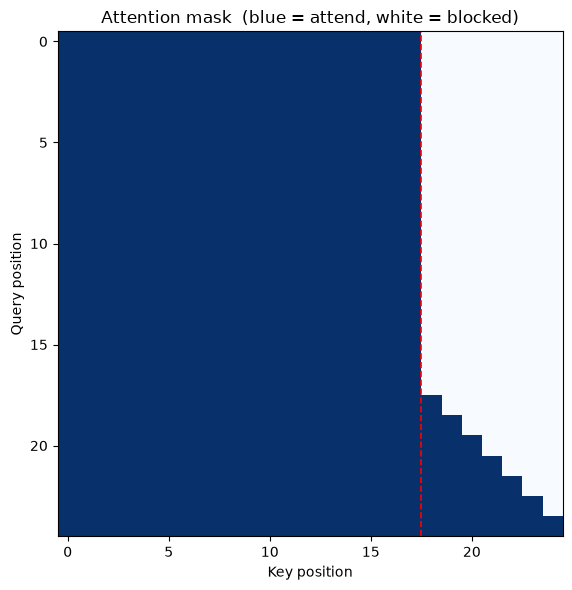

In [19]:
# Demo
from functools import partial

collate_fn = partial(collate_vlm_batch, tokenizer=tokenizer, cfg=cfg)
loader = DataLoader(dataset, batch_size=4, shuffle=True, collate_fn=collate_fn)
batch = next(iter(loader))

# Move batch to device
batch = {
    k: v.to(DEVICE) if isinstance(v, torch.Tensor) else v for k, v in batch.items()
}

vlm.eval()
with torch.no_grad():
    out = vlm(
        pixel_values=batch["pixel_values"],
        input_ids=batch["input_ids"],
        vis_ranges=batch["vis_ranges"],
        labels=batch["labels"],
        attention_mask=batch["attention_mask"],
    )

print("── Forward pass shapes ────────────────────────────────────────")
print(f"  pixel_values : {tuple(batch['pixel_values'].shape)}")
print(f"  input_ids    : {tuple(batch['input_ids'].shape)}")
print(f"  logits       : {tuple(out['logits'].shape)}")
print(f"  loss         : {out['loss'].item():.4f}")
print(f"  baseline NLL : {math.log(cfg.vocab_size):.4f}  (random guessing)")

# Visualise the attention mask pattern
seq_len = batch["input_ids"].shape[1]
vis_start = int(batch["vis_ranges"][0, 0])
vis_end = int(batch["vis_ranges"][0, 1])
mask = build_attention_mask(seq_len, vis_start, vis_end, torch.device("cpu"))

fig, ax = plt.subplots(figsize=(7, 6))
attend = (mask[0, 0] == 0.0).float().numpy()
ax.imshow(attend, cmap="Blues", vmin=0, vmax=1)
ax.set_xlabel("Key position")
ax.set_ylabel("Query position")
ax.set_title("Attention mask  (blue = attend, white = blocked)")

# Annotate regions
for label, x0, x1 in [("<vis>", 0, vis_end + 1), ("text", vis_end + 1, seq_len)]:
    ax.axvline(x0 - 0.5, color="red", linewidth=1.2, linestyle="--")
plt.tight_layout()
plt.show()

# 5) Training Loop

Production VLMs never train the backbones from scratch. They bolt a projector
between two already-expensive, already-pretrained models:

| Slot | Toy (Sections 1-4) | Production (from here on) |
|---|---|---|
| Vision encoder | `TinyViT` — random init | `google/siglip-base-patch16-224` |
| Projector | `MLPProjector` — random init | `MLPProjector` — **random init, same class** |
| Language model | `TinyLLM` — random init | `Qwen/Qwen2.5-0.5B` |


1. `Qwen2.5-0.5B` is a *text* model — its `forward()` applies its own 1-D RoPE and
we cannot feed it the 3-D `(time, height, width)` positions
(its `head_dim` of 64 isn't even divisible by 3). 
2. So on the production path, visual tokens get ordinary sequential positions.
3. Our custom **attention mask does survive** the swap: Hugging Face passes a
user-supplied 4-D mask straight through to the attention kernel, so the
bidirectional-visual / causal-text block still applies.
4. `TinyLLM.applies_own_rope = False` vs. `PretrainedLLM.applies_own_rope = True`
is the single flag `VisionLanguageModel` branches on.

## 5.1 Prod Model Configuration

Note the special-token IDs: `Qwen2.5` **already reserves** `<|vision_start|>`,
`<|vision_end|>` and `<|image_pad|>` in its vocabulary, precisely so a
vision-language variant can be built on top of it. 

No `resize_token_embeddings`, no vocabulary surgery 

In [20]:
from transformers import AutoModelForCausalLM, SiglipVisionModel, AutoImageProcessor

VISION_MODEL_ID = "google/siglip-base-patch16-224"
LLM_MODEL_ID = "Qwen/Qwen2.5-0.5B"

image_processor = AutoImageProcessor.from_pretrained(VISION_MODEL_ID)
pretrained_vit = SiglipVisionModel.from_pretrained(VISION_MODEL_ID)
pretrained_tokenizer = AutoTokenizer.from_pretrained(LLM_MODEL_ID)
pretrained_llm = AutoModelForCausalLM.from_pretrained(LLM_MODEL_ID)

# Force float32. The Qwen checkpoint ships in bfloat16, but our projector is a float32 module
pretrained_vit = pretrained_vit.float()
pretrained_llm = pretrained_llm.float()

print("── TINY vs. REAK backbone ──────────────────────────────────────")
print(f"  TinyViT : {sum(p.numel() for p in vit.parameters()):>12,} params")
print(f"  SigLIP  : {sum(p.numel() for p in pretrained_vit.parameters()):>12,} params")
print(f"  TinyLLM : {sum(p.numel() for p in llm.parameters()):>12,} params")
print(f"  Qwen2.5 : {sum(p.numel() for p in pretrained_llm.parameters()):>12,} params")

[transformers] SiglipVisionModel LOAD REPORT from: google/siglip-base-patch16-224
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.head.weight                                       | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp

── TINY vs. REAK backbone ──────────────────────────────────────
  TinyViT :    2,173,696 params
  SigLIP  :   92,884,224 params
  TinyLLM :    7,483,968 params
  Qwen2.5 :  494,032,768 params


In [21]:
vis_cfg, txt_cfg = pretrained_vit.config, pretrained_llm.config


def get_rope_theta(config) -> float:
    """
    RoPE base frequency, wherever this transformers version keeps it:
    a flat `config.rope_theta` on v4, nested in `config.rope_parameters` on v5.
    """
    rope_params = getattr(config, "rope_parameters", None)
    if rope_params:
        return rope_params["rope_theta"]
    return config.rope_theta


prod_cfg = VLMConfig(
    # ── Vision encoder — read off google/siglip-base-patch16-224
    image_size=vis_cfg.image_size,
    patch_size=vis_cfg.patch_size,
    visual_dim=vis_cfg.hidden_size,
    visual_num_heads=vis_cfg.num_attention_heads,
    visual_num_layers=vis_cfg.num_hidden_layers,
    # ── Projector — no pretrained counterpart
    projector_hidden_dim=1024,
    # ── Language model — read off Qwen/Qwen2.5-0.5B
    llm_dim=txt_cfg.hidden_size,
    llm_num_heads=txt_cfg.num_attention_heads,
    llm_num_kv_heads=txt_cfg.num_key_value_heads,
    llm_num_layers=txt_cfg.num_hidden_layers,
    llm_ffn_dim=txt_cfg.intermediate_size,
    vocab_size=txt_cfg.vocab_size,
    rope_base=get_rope_theta(txt_cfg),
    # ── Special tokens — already reserved in the Qwen2.5 vocabulary
    vision_start_id=pretrained_tokenizer.convert_tokens_to_ids("<|vision_start|>"),
    vision_end_id=pretrained_tokenizer.convert_tokens_to_ids("<|vision_end|>"),
    image_pad_id=pretrained_tokenizer.convert_tokens_to_ids("<|image_pad|>"),
    pad_token_id=pretrained_tokenizer.convert_tokens_to_ids("<|endoftext|>"),
)

print(
    f"Patch grid : {prod_cfg.patch_grid_hw} → {prod_cfg.num_patches} visual tokens per image"
)
print(
    f"GQA        : {prod_cfg.llm_num_heads} query heads / {prod_cfg.llm_num_kv_heads} KV heads "
    f"({prod_cfg.num_kv_groups}x repetition), head_dim={prod_cfg.head_dim}"
)
print(
    f"Vision IDs : start={prod_cfg.vision_start_id}, "
    f"end={prod_cfg.vision_end_id}, pad={prod_cfg.image_pad_id}"
)

Patch grid : (14, 14) → 196 visual tokens per image
GQA        : 14 query heads / 2 KV heads (7x repetition), head_dim=64
Vision IDs : start=151652, end=151653, pad=151655


In [22]:
# Wrapper for Pretrained Model
class PretrainedViT(nn.Module):
    """SiglipVisionModel behind the TinyViT interface."""

    def __init__(self, model: nn.Module, processor=image_processor):
        super().__init__()
        self.model = model

        # Our dataset emits pixels in [0, 1], but SigLIP was pretrained on
        # images normalised with the processor's mean/std (→ [-1, 1]).
        self.register_buffer(
            "pixel_mean",
            torch.tensor(processor.image_mean).view(1, 3, 1, 1),
            persistent=False,
        )
        self.register_buffer(
            "pixel_std",
            torch.tensor(processor.image_std).view(1, 3, 1, 1),
            persistent=False,
        )

    def forward(self, pixel_values: torch.Tensor) -> torch.Tensor:
        pixel_values = (pixel_values - self.pixel_mean) / self.pixel_std

        # SigLIP has no [CLS] token, so last_hidden_state is already the per-patch grid
        # Input: (batch_num, 3, H, W)
        # Output: (batch_num, num_patches, visual_dim)
        return self.model(pixel_values=pixel_values).last_hidden_state


class PretrainedLLM(nn.Module):
    """Qwen2.5 (any HF causal LM) behind the TinyLLM interface."""

    # The HF backbone applies RoPE inside its own forward()
    # VisionLanguageModel skips computing mRoPE cos/sin for us.
    applies_own_rope = True

    def __init__(self, model: nn.Module):
        super().__init__()
        self.model = model

    def get_embeddings(self, token_ids: torch.Tensor) -> torch.Tensor:
        # Input: (batch_num, seq_len)
        # Output: (batch_num, seq_len, llm_dim)
        return self.model.get_input_embeddings()(token_ids)

    def forward_from_embeddings(
        self,
        embeds: torch.Tensor,  # (batch_num, seq_len, llm_dim)
        cos: Optional[torch.Tensor],  # unused
        sin: Optional[torch.Tensor],  # unused
        attn_mask: Optional[torch.Tensor] = None,  # (batch_num, 1, seq_len, seq_len)
    ) -> torch.Tensor:

        # A 4-D attention_mask is forwarded to the attention kernel untouched,
        # so bidirectional-visual + causal-text pattern is preserved.
        # Output: (batch_num, seq_len, vocab_size)
        return self.model(
            inputs_embeds=embeds,
            attention_mask=attn_mask,
            use_cache=False,
        ).logits

In [23]:
USE_PRETRAINED = True

if USE_PRETRAINED:
    cfg = prod_cfg
    tokenizer = pretrained_tokenizer
    vit = PretrainedViT(pretrained_vit)
    llm = PretrainedLLM(pretrained_llm)

    # SigLIP's position embeddings are 224x224
    dataset = SyntheticColorDataset(num_samples=20, image_size=cfg.image_size)

    # Smaller batches / gentler LR: 20 images through a 0.5B backbone
    train_kwargs = dict(num_epochs=30, batch_size=2, lr=1e-3)
else:
    train_kwargs = dict(num_epochs=15, batch_size=16, lr=1e-3)

projector = MLPProjector(cfg.visual_dim, cfg.llm_dim, cfg.projector_hidden_dim)
vlm = VisionLanguageModel(vit, projector, llm, cfg).to(DEVICE)

print(f"Backbones    : {'SigLIP + Qwen2.5' if USE_PRETRAINED else 'TinyViT + TinyLLM'}")
print(f"Bridge       : {cfg.visual_dim} → {cfg.projector_hidden_dim} → {cfg.llm_dim}")
print(f"VLM params   : {sum(p.numel() for p in vlm.parameters()):,}")

Backbones    : SigLIP + Qwen2.5
Bridge       : 768 → 1024 → 896
VLM params   : 588,624,640


## 5.2 Stage 1 Training

In Stage 1 we **freeze everything except the MLP projector**.

- The ViT has already learned good visual representations (from SigLIP pretraining).
- The LLM has already learned good language representations.
- There is *no point* in disturbing these expensive, well-trained representations just to learn a 2-layer bridge.
- Focusing on the projector also means very few parameters to optimise, so convergence is fast.

### Gradient flow

```
image → ViT (frozen) → projector (grad ✓) → LLM (frozen) → loss
```

Only `projector.parameters()` receive gradients. Note that gradients still
*flow through* the frozen LLM to reach the projector — `requires_grad=False`
stops parameters from being updated, not activations from being differentiated.

In [24]:
def set_stage1_trainability(model: VisionLanguageModel) -> None:
    """Freeze all parameters except the MLP projector."""
    for param in model.parameters():
        param.requires_grad = False
    for param in model.projector.parameters():
        param.requires_grad = True


set_stage1_trainability(vlm)

trainable = sum(p.numel() for p in vlm.parameters() if p.requires_grad)
total = sum(p.numel() for p in vlm.parameters())
print(f"Trainable params : {trainable:,}  /  {total:,}  ({100*trainable/total:.2f}%)")
print(
    f"All projector params trainable: "
    f"{all(p.requires_grad for p in vlm.projector.parameters())}"
)
print(
    f"All LLM params frozen         : "
    f"{all(not p.requires_grad for p in vlm.llm.parameters())}"
)

Trainable params : 1,707,648  /  588,624,640  (0.29%)
All projector params trainable: True
All LLM params frozen         : True


In [25]:
# Stage 1 training loop, with AdamW with a linear warmup + cosine decay schedule.
def get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps: int,
    num_training_steps: int,
) -> torch.optim.lr_scheduler.LambdaLR:
    """Linear warmup followed by cosine decay."""

    def lr_lambda(step: int) -> float:
        if step < num_warmup_steps:
            return float(step) / max(1, num_warmup_steps)
        progress = float(step - num_warmup_steps) / max(
            1, num_training_steps - num_warmup_steps
        )
        return max(0.0, 0.5 * (1.0 + math.cos(math.pi * progress)))

    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)


def compute_token_accuracy(logits: torch.Tensor, labels: torch.Tensor) -> float:
    """
    Top-1 next-token accuracy over caption positions only.

    Uses the same shift-by-one alignment as the loss: position t predicts t+1.
    """
    # (batch_num, seq_len-1, vocab_size) → (batch_num, seq_len-1)
    preds = logits[:, :-1, :].argmax(dim=-1)
    # (batch_num, seq_len-1)
    targets = labels[:, 1:]

    mask = targets != -100
    if mask.sum() == 0:
        return 0.0
    return ((preds == targets) & mask).sum().item() / mask.sum().item()


def train_stage1(
    vlm: VisionLanguageModel,
    dataset: Dataset,
    tokenizer,
    cfg: VLMConfig,
    num_epochs: int = 15,
    batch_size: int = 16,
    lr: float = 1e-3,
    warmup_ratio: float = 0.1,
) -> Dict[str, List[float]]:
    """
    Stage 1 training: align visual features to the LLM's embedding space.

    Returns:
        history : {'train_loss': [...], 'train_acc': [...], 'lr': [...]}
    """
    collate_fn = partial(collate_vlm_batch, tokenizer=tokenizer, cfg=cfg)
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True,
        collate_fn=collate_fn,
        drop_last=True,
    )

    # Only pass projector parameters to the optimiser
    optimizer = torch.optim.AdamW(vlm.projector.parameters(), lr=lr, weight_decay=0.01)

    total_steps = num_epochs * len(loader)
    warmup_steps = int(total_steps * warmup_ratio)
    scheduler = get_cosine_schedule_with_warmup(optimizer, warmup_steps, total_steps)
    history: Dict[str, List[float]] = {"train_loss": [], "train_acc": [], "lr": []}
    vlm.train()

    for epoch in range(num_epochs):
        epoch_loss, epoch_acc, n_batches = 0.0, 0.0, 0

        for batch in loader:
            # Move tensors to device
            batch = {
                k: v.to(DEVICE) if isinstance(v, torch.Tensor) else v
                for k, v in batch.items()
            }

            # Forward pass (ViT + LLM are frozen → only projector accumulates grads)
            out = vlm(
                pixel_values=batch["pixel_values"],
                input_ids=batch["input_ids"],
                vis_ranges=batch["vis_ranges"],
                labels=batch["labels"],
                attention_mask=batch["attention_mask"],
            )
            loss = out["loss"]

            # Gradient update on projector parameters only
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(vlm.projector.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()

            epoch_loss += loss.item()
            epoch_acc += compute_token_accuracy(out["logits"], batch["labels"])
            n_batches += 1

        history["train_loss"].append(epoch_loss / n_batches)
        history["train_acc"].append(epoch_acc / n_batches)
        history["lr"].append(scheduler.get_last_lr()[0])

        if (epoch + 1) % 3 == 0 or epoch == 0:
            print(
                f"Epoch {epoch+1:3d}/{num_epochs} | loss={history['train_loss'][-1]:.4f} "
                f"| token_acc={history['train_acc'][-1]:.2%} | lr={history['lr'][-1]:.2e}"
            )
    return history


# Run Stage 1 training on whichever stack Section 5.4 bound
history = train_stage1(vlm, dataset, tokenizer, cfg, **train_kwargs)

Epoch   1/30 | loss=4.6302 | token_acc=24.29% | lr=3.33e-04
Epoch   3/30 | loss=0.3242 | token_acc=92.14% | lr=1.00e-03
Epoch   6/30 | loss=0.1116 | token_acc=95.71% | lr=9.70e-04
Epoch   9/30 | loss=0.0624 | token_acc=99.29% | lr=8.83e-04
Epoch  12/30 | loss=0.0002 | token_acc=100.00% | lr=7.50e-04
Epoch  15/30 | loss=0.0001 | token_acc=100.00% | lr=5.87e-04
Epoch  18/30 | loss=0.0001 | token_acc=100.00% | lr=4.13e-04
Epoch  21/30 | loss=0.0001 | token_acc=100.00% | lr=2.50e-04
Epoch  24/30 | loss=0.0001 | token_acc=100.00% | lr=1.17e-04
Epoch  27/30 | loss=0.0001 | token_acc=100.00% | lr=3.02e-05
Epoch  30/30 | loss=0.0001 | token_acc=100.00% | lr=0.00e+00


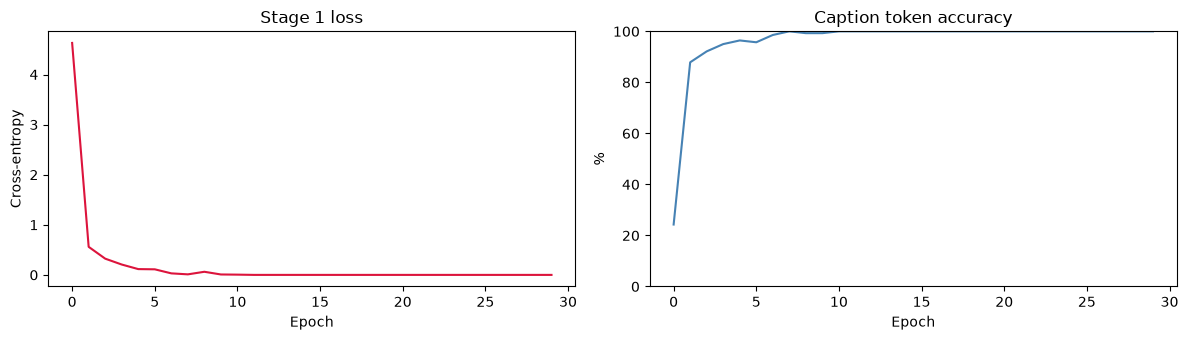

Token accuracy: 24.29% (epoch 1) → 100.00% (epoch 30)


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

axes[0].plot(history["train_loss"], color="crimson")
axes[0].set_title("Stage 1 loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy")

axes[1].plot([a * 100 for a in history["train_acc"]], color="steelblue")
axes[1].set_title("Caption token accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("%")
axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()

print(
    f"Token accuracy: {history['train_acc'][0]:.2%} (epoch 1) "
    f"→ {history['train_acc'][-1]:.2%} (epoch {len(history['train_acc'])})"
)

# 6) Greedy Caption Generation

We verify the bridge by *greedy token generation*:

1. Encode the image → project visual tokens.
2. Start with the sequence `[<vis_start>, v₁…vₙ, <vis_end>]` — no text prompt,
   so anything generated has to come from the image.
3. Autoregressively take the next token (argmax for greedy decoding).
4. Append and repeat until EOS or `max_new_tokens`.

Running this **before** any training gives us the baseline. With a randomly
initialised projector the LLM receives 196 meaningless vectors where the image
should be, so the output is unconditioned noise — that is the gap Section 7
closes.

In [27]:
@torch.no_grad()
def generate_caption(
    vlm: VisionLanguageModel,
    image: torch.Tensor,  # (3, H, W) single image
    tokenizer,
    cfg: VLMConfig,
    max_new_tokens: int = 15,
) -> str:
    """
    Greedy autoregressive caption generation for a single image.

    Steps:
        1. Build initial sequence (visual tokens only, no text prefix).
        2. At each step: forward pass → take argmax of last logit → append.
        3. Stop at EOS token or max_new_tokens.

    No KV-cache: every step re-runs the full sequence. Clear to read, and fast
    enough at this scale — production inference would cache K/V per layer.
    """
    vlm.eval()
    device = next(vlm.parameters()).device
    eos_id = get_eos_id(tokenizer)

    # Add batch dimension for model compatibility
    # (3, H, W) → (1, 3, H, W)
    pixel_values = image.unsqueeze(0).to(device)

    # Build initial token sequence: [<vis_start> pad×N <vis_end>]
    vis_ids = (
        [cfg.vision_start_id]
        + [cfg.image_pad_id] * cfg.num_patches
        + [cfg.vision_end_id]
    )

    # (1, vis_seq_len)
    current_ids = torch.tensor([vis_ids], dtype=torch.long, device=device)
    vis_start, vis_end = 0, len(vis_ids) - 1
    vis_ranges = torch.tensor([[vis_start, vis_end]], device=device)

    generated_ids: List[int] = []
    for _ in range(max_new_tokens):
        # Full forward pass on current sequence
        out = vlm(
            pixel_values=pixel_values,
            input_ids=current_ids,
            vis_ranges=vis_ranges,
        )

        # Take argmax of the last-position logit
        # (1, seq_len, vocab_size) → (1,)
        next_id = out["logits"][:, -1, :].argmax(dim=-1)

        # Stop if end-of-sequence token
        if next_id.item() == eos_id:
            break

        generated_ids.append(next_id.item())
        # Append predicted token to running sequence
        # (1, seq_len) → (1, seq_len + 1)
        current_ids = torch.cat([current_ids, next_id.unsqueeze(1)], dim=1)

    return tokenizer.decode(generated_ids, skip_special_tokens=True)


def show_captions(vlm, dataset, tokenizer, cfg, n: int = 3, title: str = "") -> None:
    """Print generated vs. target captions for the first n examples."""
    print(f"── {title} " + "─" * max(0, 58 - len(title)))
    for i in range(min(n, len(dataset))):
        sample = dataset[i]
        pred = generate_caption(vlm, sample["image"], tokenizer, cfg)
        print(f"  generated : {pred!r}")
        print(f"  target    : {sample['caption']!r}\n")


show_captions(vlm, dataset, tokenizer, cfg, title="After Stage 1 training")

── After Stage 1 training ────────────────────────────────────
  generated : 'this image shows a blue background'
  target    : 'this image shows a blue background'

  generated : 'this image shows a red background'
  target    : 'this image shows a red background'

  generated : 'this image shows a purple background'
  target    : 'this image shows a purple background'

